# Exploratory Data Analysis (EDA)
## Bicycle Theft Dataset

This notebook explores the bicycle theft dataset to understand:
- Data structure
- Missing values
- Distributions of key variables
- Patterns related to recovered vs non-recovered bikes


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
df = pd.read_csv("Bicycle_Thefts_Open_Data.csv")

df.head()

,OBJECTID,EVENT_UNIQUE_ID,PRIMARY_OFFENCE,OCC_DATE,OCC_YEAR,OCC_MONTH,OCC_DOW,OCC_DAY,OCC_DOY,OCC_HOUR,...,BIKE_COST,STATUS,HOOD_158,NEIGHBOURHOOD_158,HOOD_140,NEIGHBOURHOOD_140,LONG_WGS84,LAT_WGS84,x,y
0,1,GO-20141263544,B&E,12/26/2013 5:00:00 AM,2013,December,Thursday,26,360,19,...,1300.0,STOLEN,165,Harbourfront-CityPlace (165),077,Waterfront Communities-The Island (77),-79.395643,43.640021,-8.838283e+06,5.409903e+06
1,2,GO-20141263784,PROPERTY - FOUND,1/1/2014 5:00:00 AM,2014,January,Wednesday,1,1,18,...,NaN,RECOVERED,080,Palmerston-Little Italy (80),080,Palmerston-Little Italy (80),-79.414654,43.660525,-8.840399e+06,5.413057e+06
2,3,GO-20141261431,THEFT UNDER,1/1/2014 5:00:00 AM,2014,January,Wednesday,1,1,7,...,NaN,STOLEN,085,South Parkdale (85),085,South Parkdale (85),-79.443645,43.637657,-8.843626e+06,5.409539e+06
3,4,GO-20149000090,THEFT UNDER,1/1/2014 5:00:00 AM,2014,January,Wednesday,1,1,12,...,1019.0,STOLEN,165,Harbourfront-CityPlace (165),077,Waterfront Communities-The Island (77),-79.393760,43.642772,-8.838073e+06,5.410326e+06
4,5,GO-20141267465,THEFT UNDER,9/30/2013 4:00:00 AM,2013,September,Monday,30,273,0,...,750.0,STOLEN,078,Kensington-Chinatown (78),078,Kensington-Chinatown (78),-79.404678,43.648964,-8.839288e+06,5.411278e+06


In [3]:
df.shape

df.info()

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39473 entries, 0 to 39472
Data columns (total 35 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   OBJECTID           39473 non-null  int64  
 1   EVENT_UNIQUE_ID    39473 non-null  object 
 2   PRIMARY_OFFENCE    39473 non-null  object 
 3   OCC_DATE           39473 non-null  object 
 4   OCC_YEAR           39473 non-null  int64  
 5   OCC_MONTH          39473 non-null  object 
 6   OCC_DOW            39473 non-null  object 
 7   OCC_DAY            39473 non-null  int64  
 8   OCC_DOY            39473 non-null  int64  
 9   OCC_HOUR           39473 non-null  int64  
 10  REPORT_DATE        39473 non-null  object 
 11  REPORT_YEAR        39473 non-null  int64  
 12  REPORT_MONTH       39473 non-null  object 
 13  REPORT_DOW         39473 non-null  object 
 14  REPORT_DAY         39473 non-null  int64  
 15  REPORT_DOY         39473 non-null  int64  
 16  REPORT_HOUR        394

,OBJECTID,OCC_YEAR,OCC_DAY,OCC_DOY,OCC_HOUR,REPORT_YEAR,REPORT_DAY,REPORT_DOY,REPORT_HOUR,BIKE_SPEED,BIKE_COST,LONG_WGS84,LAT_WGS84,x,y
count,39473.000000,39473.000000,39473.000000,39473.000000,39473.000000,39473.000000,39473.000000,39473.000000,39473.000000,37917.000000,36869.000000,39473.000000,39473.000000,3.947300e+04,3.947300e+04
mean,19737.000000,2019.067616,15.659539,200.162288,13.301143,2019.090948,15.992704,201.244142,14.295924,14.110847,1007.289480,-78.708722,43.297335,-8.761815e+06,5.368449e+06
std,11395.017925,3.231275,8.638106,77.765684,6.514874,3.209464,8.604319,77.997271,5.092453,13.185610,1657.139264,7.347741,4.042019,8.179468e+05,5.011839e+05
min,1.000000,1975.000000,1.000000,1.000000,0.000000,2014.000000,1.000000,1.000000,0.000000,0.000000,-1200.000000,-79.622226,0.000000,-8.863506e+06,5.664924e-09
25%,9869.000000,2016.000000,8.000000,149.000000,9.000000,2016.000000,9.000000,150.000000,11.000000,5.000000,400.000000,-79.418846,43.650267,-8.840865e+06,5.411479e+06
50%,19737.000000,2019.000000,16.000000,203.000000,14.000000,2019.000000,16.000000,205.000000,14.000000,14.000000,700.000000,-79.390787,43.662122,-8.837742e+06,5.413303e+06
75%,29605.000000,2022.000000,23.000000,257.000000,18.000000,2022.000000,23.000000,259.000000,18.000000,21.000000,1200.000000,-79.373022,43.683415,-8.835764e+06,5.416580e+06
max,39473.000000,2025.000000,31.000000,366.000000,23.000000,2025.000000,31.000000,366.000000,23.000000,1500.000000,120000.000000,0.000000,43.837237,6.327780e-09,5.440289e+06


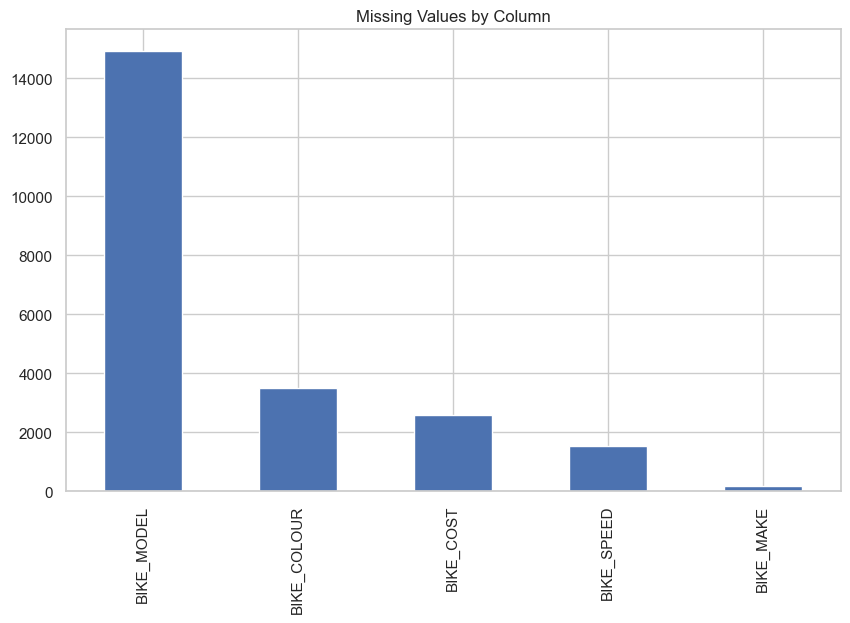

In [4]:
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

missing[missing > 0].plot(kind="bar")
plt.title("Missing Values by Column")
plt.show()

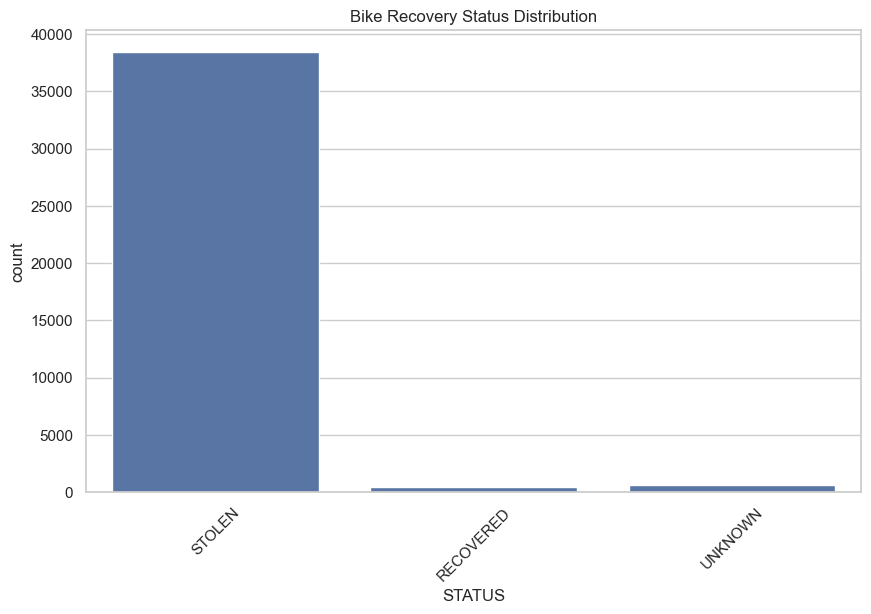

In [7]:
df["STATUS"].value_counts()

sns.countplot(data=df, x="STATUS")
plt.title("Bike Recovery Status Distribution")
plt.xticks(rotation=45)
plt.show()

In [6]:
df.columns

Index(['OBJECTID', 'EVENT_UNIQUE_ID', 'PRIMARY_OFFENCE', 'OCC_DATE',
       'OCC_YEAR', 'OCC_MONTH', 'OCC_DOW', 'OCC_DAY', 'OCC_DOY', 'OCC_HOUR',
       'REPORT_DATE', 'REPORT_YEAR', 'REPORT_MONTH', 'REPORT_DOW',
       'REPORT_DAY', 'REPORT_DOY', 'REPORT_HOUR', 'DIVISION', 'LOCATION_TYPE',
       'PREMISES_TYPE', 'BIKE_MAKE', 'BIKE_MODEL', 'BIKE_TYPE', 'BIKE_SPEED',
       'BIKE_COLOUR', 'BIKE_COST', 'STATUS', 'HOOD_158', 'NEIGHBOURHOOD_158',
       'HOOD_140', 'NEIGHBOURHOOD_140', 'LONG_WGS84', 'LAT_WGS84', 'x', 'y'],
      dtype='object')

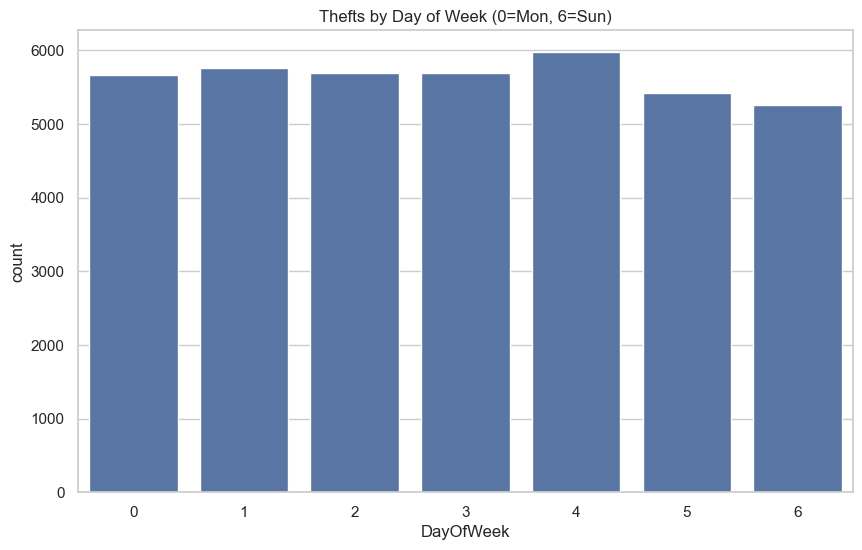

In [8]:
df["OCC_DATE"] = pd.to_datetime(df["OCC_DATE"], errors="coerce")

df["Year"] = df["OCC_DATE"].dt.year
df["Month"] = df["OCC_DATE"].dt.month
df["DayOfWeek"] = df["OCC_DATE"].dt.dayofweek

sns.countplot(data=df, x="DayOfWeek")
plt.title("Thefts by Day of Week (0=Mon, 6=Sun)")
plt.show()

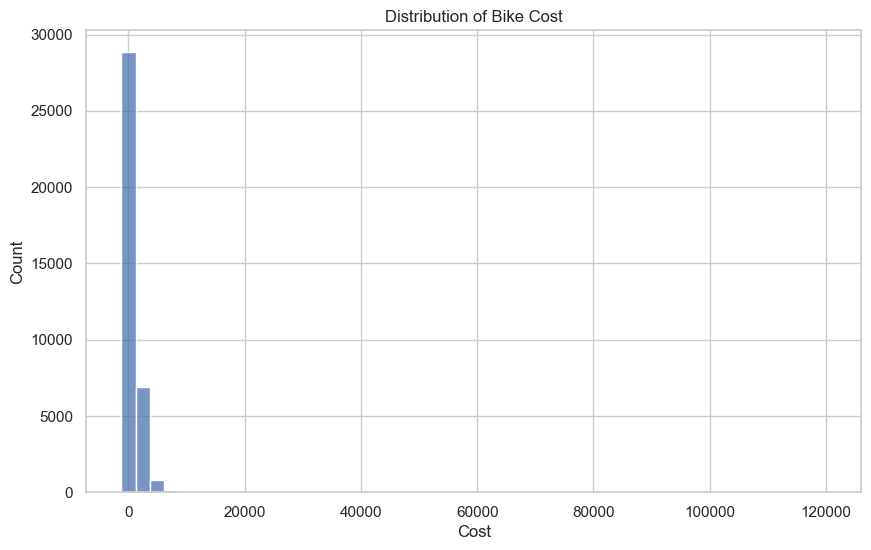

In [10]:
sns.histplot(df["BIKE_COST"].dropna(), bins=50)
plt.title("Distribution of Bike Cost")
plt.xlabel("Cost")
plt.show()

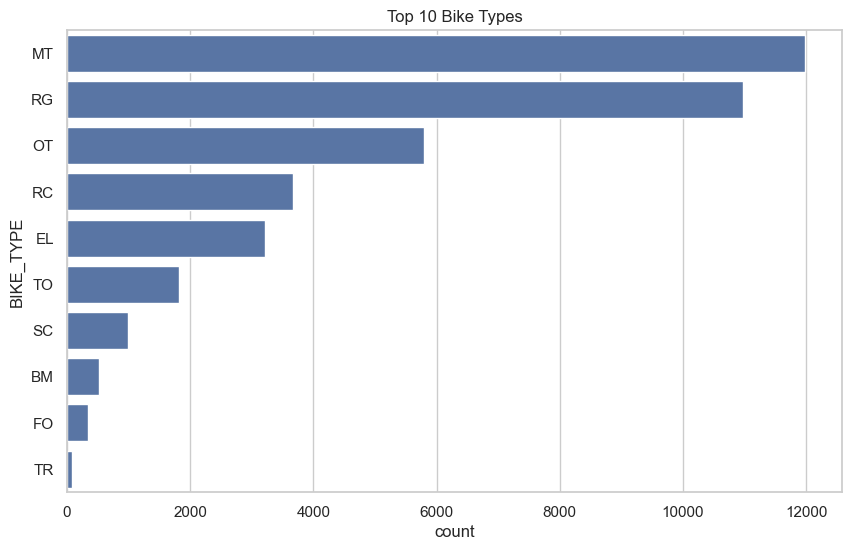

In [11]:
df["BIKE_TYPE"].value_counts().head(10)

sns.countplot(data=df, y="BIKE_TYPE", order=df["BIKE_TYPE"].value_counts().index[:10])
plt.title("Top 10 Bike Types")
plt.show()


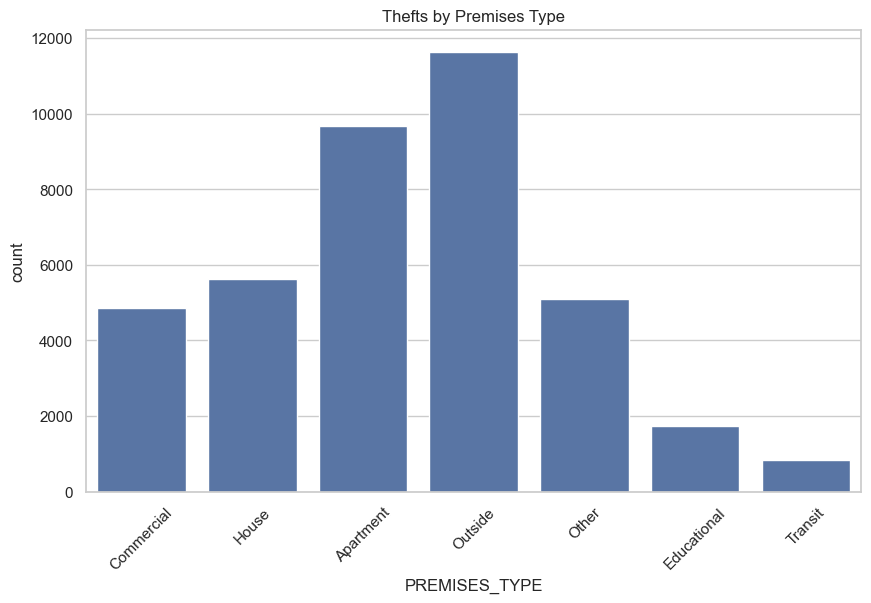

In [12]:
df["PREMISES_TYPE"].value_counts()

sns.countplot(data=df, x="PREMISES_TYPE")
plt.title("Thefts by Premises Type")
plt.xticks(rotation=45)
plt.show()

## Exploration Data Analysis Summary

Key observations from the exploratory analysis:

- The dataset contains missing values in several categorical and numeric fields.
- Most bikes are **not recovered**, indicating class imbalance.
- Theft frequency varies by **day of week** and **premises type**.
- Bike cost is highly skewed and may benefit from transformation.
- Several categorical variables will require encoding before modeling.

These findings informed the feature engineering and preprocessing steps used in `data_prep.py`.